# BÀI 6 — TRANSFER LEARNING: Oxford Flowers-102 với ResNet18 (ImageNet-1K)

So sánh 4 chiến lược trên cùng kiến trúc: **Scratch**, **Linear Probe**, **Partial FT** (layer4 + head), **Full FT** (LR theo tầng).

**Quy tắc:** chọn mô hình chỉ bằng **validation loss**; test chỉ đánh giá **một lần** sau khi đã chọn.
**Lưu ý đối chứng:** Scratch/Partial/Full chạy 5 epoch, Linear Probe chạy 25 epoch trên embeddings đã cache, nên chưa phải so sánh cùng ngân sách. Mọi nhận xét chỉ dựa trên **một seed, một lần chạy**.

## 0. Thiết lập và tái lập

In [1]:
import copy
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, models, transforms
from torchvision.models import ResNet18_Weights

SEED = 42
BATCH_SIZE = 32
IMAGE_SIZE = 224
NUM_CLASSES = 102
EPOCHS_SCRATCH = 5
EPOCHS_PROBE = 25
EPOCHS_PARTIAL = 5
EPOCHS_FULL = 5
PATIENCE = 4

DATA_DIR = Path("./data")          # một thư mục dữ liệu duy nhất
OUTPUT_DIR = Path("./bai6_transfer_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 0 if DEVICE.type == "cpu" else 2
PIN_MEMORY = DEVICE.type == "cuda"
WEIGHTS = ResNet18_Weights.IMAGENET1K_V1


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
print("Torch:", torch.__version__, "| Torchvision:", __import__("torchvision").__version__)
print("Thiết bị:", DEVICE, "| Workers:", NUM_WORKERS, "| Seed:", SEED)
if DEVICE.type == "cpu":
    print("CẢNH BÁO: đang chạy CPU (bài giảng yêu cầu GPU CUDA) - sẽ chậm hơn nhiều.")

Torch: 2.15.0+cpu | Torchvision: 0.29.2+cpu
Thiết bị: cpu | Workers: 0 | Seed: 42
CẢNH BÁO: đang chạy CPU (bài giảng yêu cầu GPU CUDA) - sẽ chậm hơn nhiều.


## 1. Dữ liệu và tiền xử lý

Flowers-102: 1.020 train (10 ảnh/lớp), 1.020 validation, 6.149 test. Train dùng augmentation nhẹ; validation/test dùng biến đổi **xác định** của `WEIGHTS.transforms()` (Resize 256 → CenterCrop 224 → Normalize ImageNet). Linear probe cache embedding từ ảnh train **không** augmentation (`flowers_train_clean`).

100.0%
100.0%
100.0%


Train: 1020 | Validation: 1020 | Số lớp: 102
Một batch: (32, 3, 224, 224) | Nhãn: (32,)


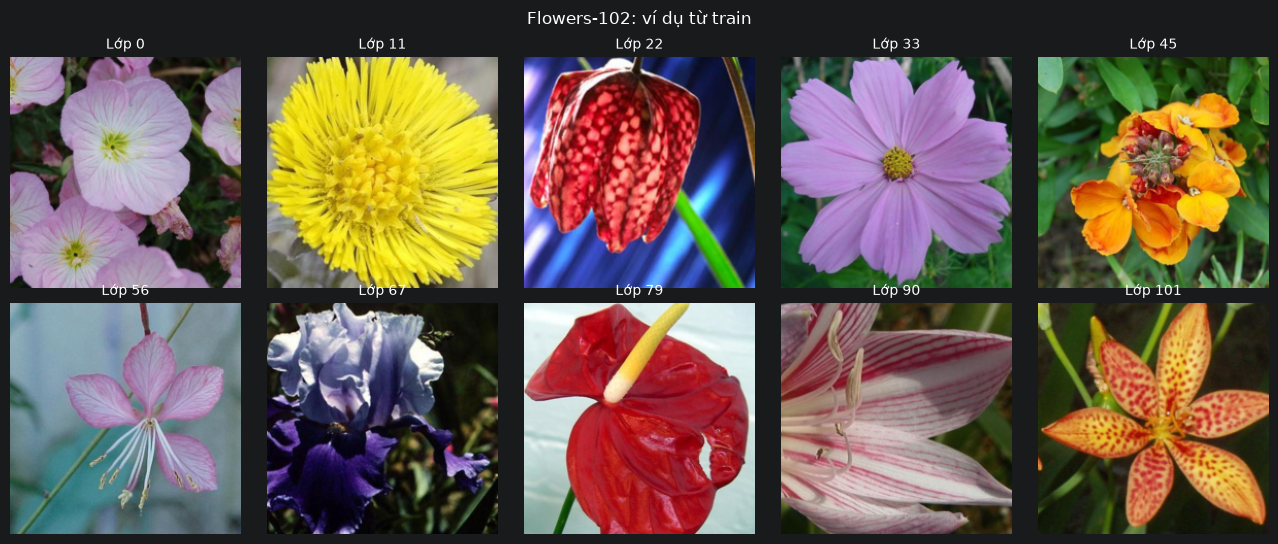

In [2]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.72, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.12),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = WEIGHTS.transforms()

flowers_train = datasets.Flowers102(DATA_DIR, split="train", download=True, transform=train_transform)
flowers_train_clean = datasets.Flowers102(DATA_DIR, split="train", download=False, transform=eval_transform)
flowers_val = datasets.Flowers102(DATA_DIR, split="val", download=False, transform=eval_transform)

assert len(flowers_train) == len(flowers_train_clean) == 1020
assert len(flowers_val) == 1020
assert len({label for _, label in flowers_train_clean}) == NUM_CLASSES


def make_loader(ds, shuffle):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)


train_loader = make_loader(flowers_train, True)
train_clean_loader = make_loader(flowers_train_clean, False)
val_loader = make_loader(flowers_val, False)

print("Train:", len(flowers_train), "| Validation:", len(flowers_val), "| Số lớp:", NUM_CLASSES)
sample_images, sample_labels = next(iter(train_loader))
print("Một batch:", tuple(sample_images.shape), "| Nhãn:", tuple(sample_labels.shape))
assert sample_images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)

# Hiển thị 10 ảnh train (đã hoàn tác Normalize) - không dùng ảnh test
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for ax, idx in zip(axes.flat, np.linspace(0, len(flowers_train_clean) - 1, 10, dtype=int)):
    img, target = flowers_train_clean[int(idx)]
    arr = img.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
    ax.imshow(np.clip(arr, 0.0, 1.0))
    ax.set_title(f"Lớp {target}", fontsize=10)
    ax.axis("off")
fig.suptitle("Flowers-102: ví dụ từ train")
plt.tight_layout()
plt.show()

## 2. Mô hình, đóng băng, BatchNorm và learning rate theo tầng

- `requires_grad=False` **không** giống `model.eval()`: BatchNorm vẫn cập nhật running statistics nếu mô hình ở chế độ `train()`.
- Vì vậy với **probe/partial**, hàm `set_training_mode` đặt **mọi BatchNorm ở `eval()`** khi huấn luyện (với ít dữ liệu, giữ thống kê ImageNet ổn định hơn). Đây là lựa chọn thiết kế.
- **Full FT** dùng 4 nhóm learning rate: tầng thấp `1e-5` → layer3 `3e-5` → layer4 `1e-4` → head `1e-3`.

In [3]:
def count_parameters(model: nn.Module) -> dict:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"Total": total, "Trainable": trainable, "Frozen": total - trainable}


def build_resnet18(num_classes: int = NUM_CLASSES, pretrained: bool = True) -> nn.Module:
    model = models.resnet18(weights=WEIGHTS if pretrained else None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def configure_trainable(model: nn.Module, strategy: str) -> nn.Module:
    if strategy not in ("scratch", "probe", "partial", "full"):
        raise ValueError(f"Chiến lược không được hỗ trợ: {strategy}")
    for p in model.parameters():
        p.requires_grad = strategy in ("scratch", "full")
    if strategy in ("probe", "partial"):
        for p in model.fc.parameters():
            p.requires_grad = True
    if strategy == "partial":
        for p in model.layer4.parameters():
            p.requires_grad = True
    return model


def set_training_mode(model: nn.Module, strategy: str) -> None:
    """train() nhưng giữ BatchNorm ở eval() với probe/partial."""
    model.train()
    if strategy in ("probe", "partial"):
        for m in model.modules():
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                m.eval()


def build_optimizer(model: nn.Module, strategy: str) -> torch.optim.Optimizer:
    if strategy == "scratch":
        return torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                 lr=1e-3, weight_decay=1e-4)
    if strategy == "probe":
        return torch.optim.AdamW(model.fc.parameters(), lr=3e-3, weight_decay=1e-3)
    if strategy == "partial":
        return torch.optim.AdamW([
            {"params": model.layer4.parameters(), "lr": 1e-4},
            {"params": model.fc.parameters(), "lr": 1e-3},
        ], weight_decay=1e-4)
    if strategy == "full":
        return torch.optim.AdamW([
            {"params": list(model.conv1.parameters()) + list(model.bn1.parameters()) +
                       list(model.layer1.parameters()) + list(model.layer2.parameters()), "lr": 1e-5},
            {"params": model.layer3.parameters(), "lr": 3e-5},
            {"params": model.layer4.parameters(), "lr": 1e-4},
            {"params": model.fc.parameters(), "lr": 1e-3},
        ], weight_decay=1e-4)
    raise ValueError(strategy)


base = build_resnet18(pretrained=False)
demos = {s: configure_trainable(copy.deepcopy(base), s) for s in ("scratch", "probe", "partial", "full")}
display(pd.DataFrame([{"Chiến lược": s, **count_parameters(m)} for s, m in demos.items()]))
assert demos["probe"].fc.out_features == NUM_CLASSES
assert 0 < count_parameters(demos["probe"])["Trainable"] < count_parameters(demos["partial"])["Trainable"] \
       < count_parameters(demos["full"])["Trainable"]
print("Learning rate Full FT:", [g["lr"] for g in build_optimizer(demos["full"], "full").param_groups])
del base, demos

,Chiến lược,Total,Trainable,Frozen
0,scratch,11228838,11228838,0
1,probe,11228838,52326,11176512
2,partial,11228838,8446054,2782784
3,full,11228838,11228838,0


Learning rate Full FT: [1e-05, 3e-05, 0.0001, 0.001]


## 3. Hàm huấn luyện và đánh giá

`zero_grad → forward → CrossEntropyLoss(logits) → backward → step`. Loss cộng theo **số mẫu**. Checkpoint tốt nhất chọn theo **val_loss**; model được khôi phục từ checkpoint đó trước khi tổng kết.

In [4]:
def evaluate(model: nn.Module, loader: DataLoader) -> dict:
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss, total, c1, c5 = 0.0, 0, 0, 0
    ys, ps = [], []
    with torch.inference_mode():
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            logits = model(x)
            total_loss += criterion(logits, y).item()
            pred = logits.argmax(dim=1)
            c1 += int((pred == y).sum())
            c5 += int((logits.topk(5, dim=1).indices == y.unsqueeze(1)).any(dim=1).sum())
            total += y.size(0)
            ys.extend(y.cpu().tolist())
            ps.extend(pred.cpu().tolist())
    return {"loss": total_loss / total, "top1": c1 / total, "top5": c5 / total,
            "macro_f1": f1_score(ys, ps, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0),
            "y_true": np.asarray(ys), "y_pred": np.asarray(ps)}


def fit_model(name, model, train_data, val_data, strategy, epochs):
    model = model.to(DEVICE)
    optimizer = build_optimizer(model, strategy)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, epochs))
    criterion = nn.CrossEntropyLoss()
    history, best_state = [], None
    best_loss, best_epoch, bad = float("inf"), 0, 0
    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        set_training_mode(model, strategy)
        run_loss, run_correct, seen = 0.0, 0, 0
        for x, y in train_data:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * y.size(0)
            run_correct += (logits.argmax(dim=1) == y).sum().item()
            seen += y.size(0)
        scheduler.step()

        v = evaluate(model, val_data)
        row = {"epoch": epoch, "train_loss": run_loss / seen, "train_acc": run_correct / seen,
               "val_loss": v["loss"], "val_top1": v["top1"], "val_macro_f1": v["macro_f1"], "val_top5": v["top5"]}
        history.append(row)
        print(f"[{name}] {epoch:02d}/{epochs:02d} | train_loss={row['train_loss']:.4f} | "
              f"val_loss={row['val_loss']:.4f} | val_top1={row['val_top1']:.4f} | "
              f"macro_f1={row['val_macro_f1']:.4f} | top5={row['val_top5']:.4f}")

        if v["loss"] < best_loss - 1e-6:
            best_loss, best_epoch, bad = v["loss"], epoch, 0
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"[{name}] Early stopping tại epoch {epoch}.")
                break

    model.load_state_dict(best_state)          # khôi phục checkpoint tốt nhất
    m = evaluate(model, val_data)
    summary = {"Chiến lược": name, "Best epoch": best_epoch, "Trainable": count_parameters(model)["Trainable"],
               "Val loss": m["loss"], "Val Top-1": m["top1"], "Val Macro-F1": m["macro_f1"],
               "Val Top-5": m["top5"], "Thời gian (s)": round(time.perf_counter() - start, 1)}
    print(f"[{name}] BEST epoch={best_epoch}, val_loss={m['loss']:.4f}, val_top1={m['top1']:.4f}")
    return model, pd.DataFrame(history), summary


fitted, histories, summaries = {}, {}, {}

## 4. Thí nghiệm A — Scratch (baseline)
Khởi tạo `weights=None`, tối ưu toàn bộ mạng. 5 epoch **không** đủ để scratch hội tụ.

In [5]:
set_seed(SEED)
m = configure_trainable(build_resnet18(pretrained=False), "scratch")
m, histories["Scratch"], summaries["Scratch"] = fit_model(
    "Scratch", m, train_loader, val_loader, "scratch", EPOCHS_SCRATCH)
fitted["Scratch"] = m.cpu()
display(pd.DataFrame([summaries["Scratch"]]).round(4))

[Scratch] 01/05 | train_loss=4.5520 | val_loss=8.4842 | val_top1=0.0333 | macro_f1=0.0081 | top5=0.1775
[Scratch] 02/05 | train_loss=3.8732 | val_loss=4.3059 | val_top1=0.0637 | macro_f1=0.0246 | top5=0.2363
[Scratch] 03/05 | train_loss=3.5389 | val_loss=3.8278 | val_top1=0.1127 | macro_f1=0.0670 | top5=0.3745
[Scratch] 04/05 | train_loss=3.2421 | val_loss=3.3993 | val_top1=0.1539 | macro_f1=0.1112 | top5=0.4314
[Scratch] 05/05 | train_loss=2.9665 | val_loss=3.1958 | val_top1=0.2098 | macro_f1=0.1673 | top5=0.5000
[Scratch] BEST epoch=5, val_loss=3.1958, val_top1=0.2098


,Chiến lược,Best epoch,Trainable,Val loss,Val Top-1,Val Macro-F1,Val Top-5,Thời gian (s)
0,Scratch,5,11228838,3.1958,0.2098,0.1673,0.5,461.4


## 5. Thí nghiệm B — Frozen backbone + Linear Probe

Cache embedding 512 chiều từ backbone ImageNet đóng băng (ảnh không augmentation), rồi chỉ học `Linear(512, 102)`.
Thời gian của probe **chưa gồm** thời gian cache embedding nên không so sánh trực tiếp tổng chi phí.

In [6]:
class LinearProbe(nn.Module):
    def __init__(self, in_features: int = 512, out_features: int = NUM_CLASSES):
        super().__init__()
        self.fc = nn.Linear(in_features, out_features)

    def forward(self, x):
        return self.fc(x)


def extract_features(pretrained_model: nn.Module, loader: DataLoader) -> TensorDataset:
    backbone = copy.deepcopy(pretrained_model)
    backbone.fc = nn.Identity()
    backbone = backbone.to(DEVICE).eval()
    feats, labels = [], []
    with torch.inference_mode():
        for x, y in loader:
            feats.append(backbone(x.to(DEVICE, non_blocking=True)).cpu())
            labels.append(y.clone())
    return TensorDataset(torch.cat(feats), torch.cat(labels))


pretrained_probe = build_resnet18(pretrained=True)
cached_train = extract_features(pretrained_probe, train_clean_loader)
cached_val = extract_features(pretrained_probe, val_loader)
print("Cached train:", tuple(cached_train.tensors[0].shape), "| Cached val:", tuple(cached_val.tensors[0].shape))

probe_train_loader = DataLoader(cached_train, batch_size=128, shuffle=True)
probe_val_loader = DataLoader(cached_val, batch_size=256, shuffle=False)

set_seed(SEED)
head = LinearProbe()
head, histories["Linear Probe"], summaries["Linear Probe"] = fit_model(
    "Linear Probe", head, probe_train_loader, probe_val_loader, "probe", EPOCHS_PROBE)

# Ghép head đã học vào backbone pretrained để suy luận trên ảnh
pretrained_probe.fc.load_state_dict(head.fc.cpu().state_dict())
fitted["Linear Probe"] = configure_trainable(pretrained_probe.cpu(), "probe")
summaries["Linear Probe"]["Trainable"] = count_parameters(fitted["Linear Probe"])["Trainable"]
display(pd.DataFrame([summaries["Linear Probe"]]).round(4))
del head, cached_train, cached_val

Cached train: (1020, 512) | Cached val: (1020, 512)
[Linear Probe] 01/25 | train_loss=4.5336 | val_loss=3.7540 | val_top1=0.2353 | macro_f1=0.1918 | top5=0.4559
[Linear Probe] 02/25 | train_loss=3.1316 | val_loss=2.7940 | val_top1=0.5598 | macro_f1=0.5193 | top5=0.7794
[Linear Probe] 03/25 | train_loss=2.1006 | val_loss=2.1581 | val_top1=0.6676 | macro_f1=0.6501 | top5=0.8824
[Linear Probe] 04/25 | train_loss=1.4595 | val_loss=1.7366 | val_top1=0.7441 | macro_f1=0.7342 | top5=0.9206
[Linear Probe] 05/25 | train_loss=1.0568 | val_loss=1.4749 | val_top1=0.7745 | macro_f1=0.7681 | top5=0.9333
[Linear Probe] 06/25 | train_loss=0.7972 | val_loss=1.3045 | val_top1=0.8049 | macro_f1=0.8013 | top5=0.9441
[Linear Probe] 07/25 | train_loss=0.6286 | val_loss=1.1839 | val_top1=0.8127 | macro_f1=0.8080 | top5=0.9402
[Linear Probe] 08/25 | train_loss=0.5175 | val_loss=1.1060 | val_top1=0.8078 | macro_f1=0.8085 | top5=0.9559
[Linear Probe] 09/25 | train_loss=0.4288 | val_loss=1.0426 | val_top1=0.8275

,Chiến lược,Best epoch,Trainable,Val loss,Val Top-1,Val Macro-F1,Val Top-5,Thời gian (s)
0,Linear Probe,25,52326,0.8378,0.848,0.847,0.9608,0.7


## 6. Thí nghiệm C — Partial fine-tuning (`layer4` + head)
Mở `layer4` và head; BatchNorm giữ ở `eval()`; LR `1e-4` (layer4) và `1e-3` (head).

In [7]:
set_seed(SEED)
m = configure_trainable(build_resnet18(pretrained=True), "partial")
print("Tham số partial:", count_parameters(m))
m, histories["Partial FT"], summaries["Partial FT"] = fit_model(
    "Partial FT", m, train_loader, val_loader, "partial", EPOCHS_PARTIAL)
fitted["Partial FT"] = m.cpu()
display(pd.DataFrame([summaries["Partial FT"]]).round(4))

Tham số partial: {'Total': 11228838, 'Trainable': 8446054, 'Frozen': 2782784}
[Partial FT] 01/05 | train_loss=4.5019 | val_loss=3.7159 | val_top1=0.2078 | macro_f1=0.1335 | top5=0.4020
[Partial FT] 02/05 | train_loss=2.3380 | val_loss=1.5174 | val_top1=0.6216 | macro_f1=0.6053 | top5=0.8471
[Partial FT] 03/05 | train_loss=0.6291 | val_loss=0.8999 | val_top1=0.7441 | macro_f1=0.7426 | top5=0.9412
[Partial FT] 04/05 | train_loss=0.2114 | val_loss=0.7778 | val_top1=0.7794 | macro_f1=0.7782 | top5=0.9441
[Partial FT] 05/05 | train_loss=0.0856 | val_loss=0.6448 | val_top1=0.8304 | macro_f1=0.8295 | top5=0.9618
[Partial FT] BEST epoch=5, val_loss=0.6448, val_top1=0.8304


,Chiến lược,Best epoch,Trainable,Val loss,Val Top-1,Val Macro-F1,Val Top-5,Thời gian (s)
0,Partial FT,5,8446054,0.6448,0.8304,0.8295,0.9618,272.9


## 7. Thí nghiệm D — Full fine-tuning với LR theo tầng
Mở toàn bộ mạng, 4 nhóm LR: `1e-5 / 3e-5 / 1e-4 / 1e-3`. BatchNorm ở chế độ `train()`.

In [8]:
set_seed(SEED)
m = configure_trainable(build_resnet18(pretrained=True), "full")
m, histories["Full FT"], summaries["Full FT"] = fit_model(
    "Full FT", m, train_loader, val_loader, "full", EPOCHS_FULL)
fitted["Full FT"] = m.cpu()
display(pd.DataFrame([summaries["Full FT"]]).round(4))

[Full FT] 01/05 | train_loss=4.0787 | val_loss=2.5484 | val_top1=0.5765 | macro_f1=0.5469 | top5=0.7990
[Full FT] 02/05 | train_loss=1.7314 | val_loss=1.4270 | val_top1=0.7755 | macro_f1=0.7583 | top5=0.9324
[Full FT] 03/05 | train_loss=0.8120 | val_loss=1.0899 | val_top1=0.8343 | macro_f1=0.8318 | top5=0.9598
[Full FT] 04/05 | train_loss=0.4914 | val_loss=0.9551 | val_top1=0.8598 | macro_f1=0.8582 | top5=0.9667
[Full FT] 05/05 | train_loss=0.3758 | val_loss=0.9333 | val_top1=0.8529 | macro_f1=0.8506 | top5=0.9696
[Full FT] BEST epoch=5, val_loss=0.9333, val_top1=0.8529


,Chiến lược,Best epoch,Trainable,Val loss,Val Top-1,Val Macro-F1,Val Top-5,Thời gian (s)
0,Full FT,5,11228838,0.9333,0.8529,0.8506,0.9696,458.0


## 8. So sánh trên validation và chọn mô hình
Xếp theo `Val loss` tăng dần; nếu bằng nhau thì theo `Val Macro-F1` giảm dần. Chỉ mô hình đứng đầu được đưa sang test.

,Chiến lược,Best epoch,Trainable,Val loss,Val Top-1,Val Macro-F1,Val Top-5,Thời gian (s)
0,Partial FT,5,8446054,0.6448,0.8304,0.8295,0.9618,272.9
1,Linear Probe,25,52326,0.8378,0.8480,0.8470,0.9608,0.7
2,Full FT,5,11228838,0.9333,0.8529,0.8506,0.9696,458.0
3,Scratch,5,11228838,3.1958,0.2098,0.1673,0.5000,461.4


Mô hình được chọn CHỈ từ validation: Partial FT


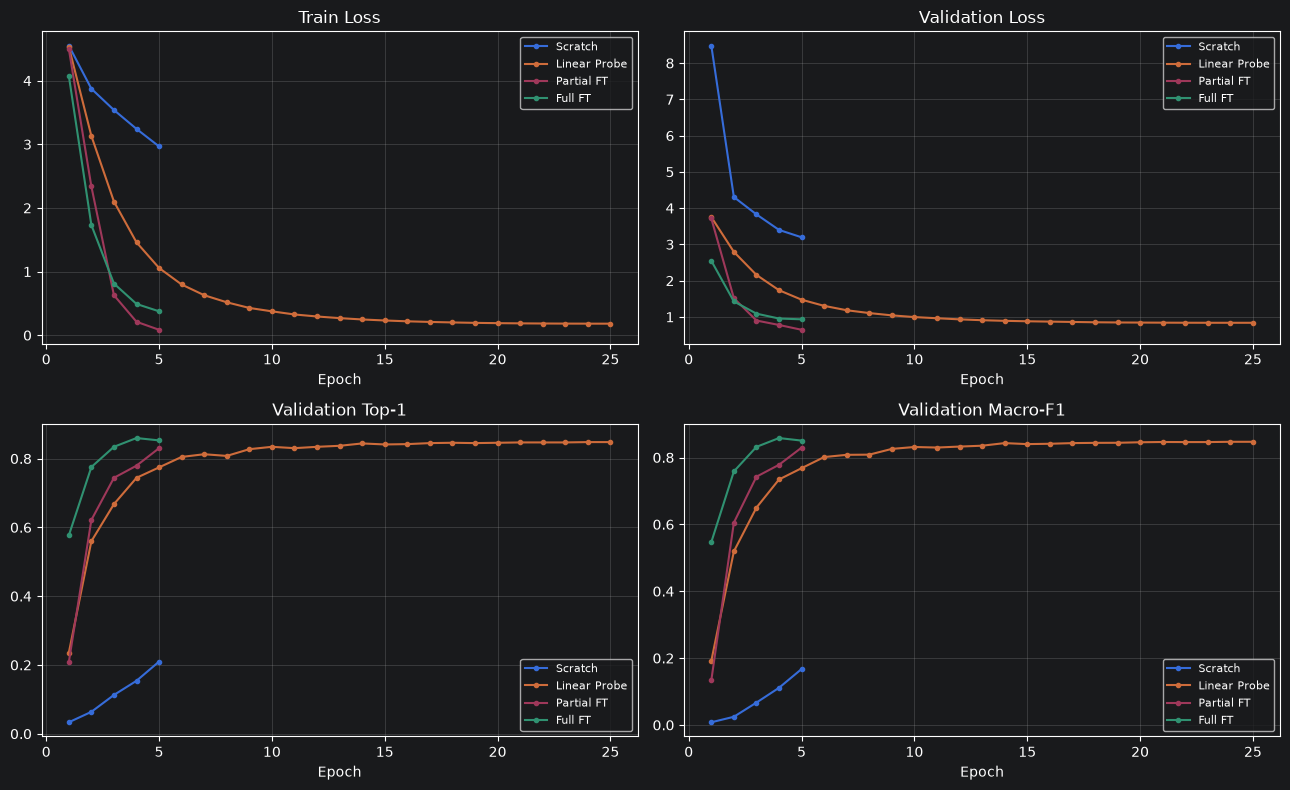

In [9]:
comparison = pd.DataFrame(summaries.values()).sort_values(
    ["Val loss", "Val Macro-F1"], ascending=[True, False]).reset_index(drop=True)
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR / "validation_comparison.csv", index=False)

selected_name = str(comparison.iloc[0]["Chiến lược"])
best_model = fitted[selected_name].to(DEVICE).eval()
print("Mô hình được chọn CHỈ từ validation:", selected_name)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
panels = [("train_loss", "Train Loss"), ("val_loss", "Validation Loss"),
          ("val_top1", "Validation Top-1"), ("val_macro_f1", "Validation Macro-F1")]
for ax, (col, title) in zip(axes.flat, panels):
    for name, h in histories.items():
        ax.plot(h["epoch"], h[col], marker="o", markersize=3, label=name)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "learning_curves_comparison.png", dpi=150)
plt.show()

## 9. Đánh giá test đúng một lần và phân tích lỗi
Test chỉ dùng để ước lượng hiệu năng ngoài mẫu **sau khi** đã chọn mô hình; không quay lại chỉnh siêu tham số.

,Mô hình,Test loss,Test Top-1,Test Macro-F1,Test Top-5,N test
0,Partial FT,0.7247,0.8026,0.8031,0.9483,6149


10 lớp có F1 thấp nhất:


,precision,recall,f1-score,support
Flower 002,0.214,0.450,0.290,20.0
Flower 003,0.471,0.444,0.457,36.0
Flower 038,0.350,0.667,0.459,21.0
Flower 066,0.380,0.864,0.528,22.0
Flower 052,0.853,0.397,0.542,73.0
Flower 083,1.000,0.379,0.549,66.0
Flower 000,0.436,0.850,0.576,20.0
Flower 082,0.582,0.577,0.579,111.0
Flower 039,0.429,0.894,0.579,47.0
Flower 006,0.417,1.000,0.588,20.0


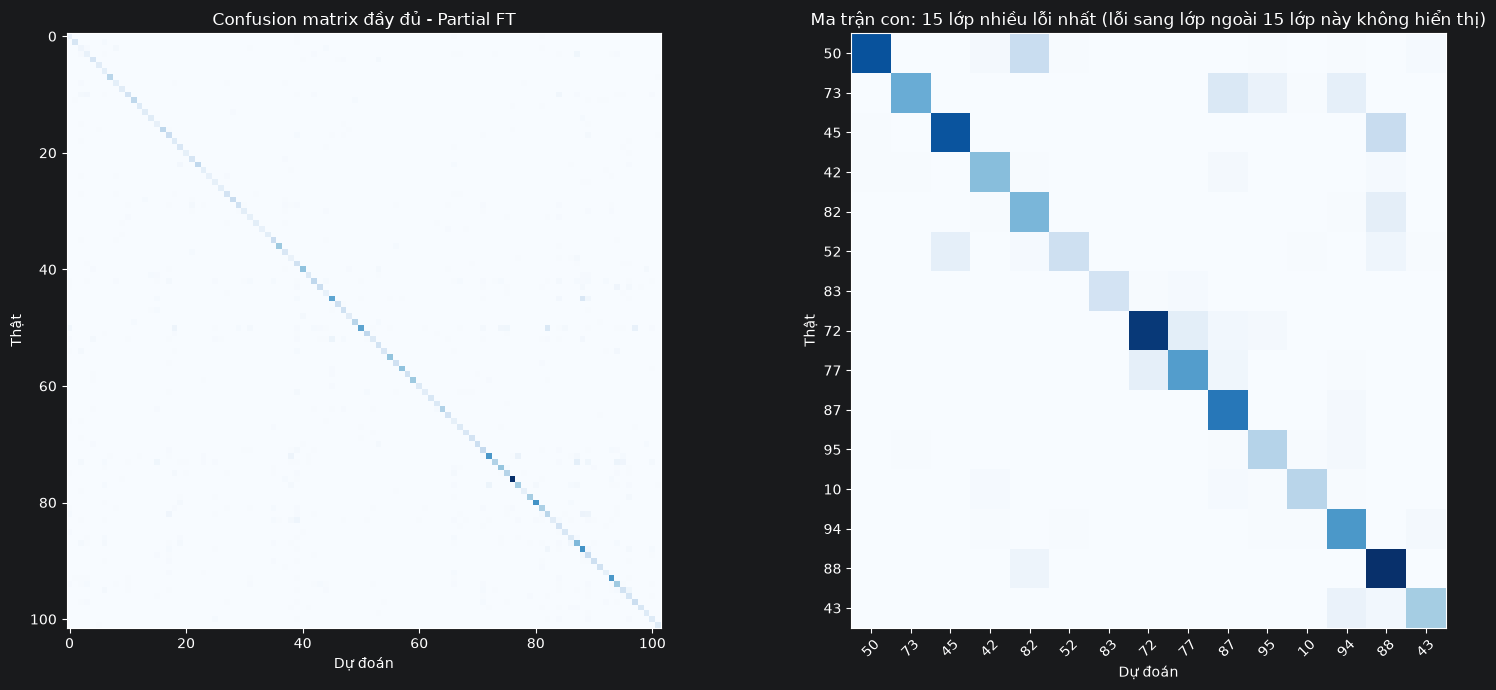

Tổng ảnh dự đoán sai: 1214 / 6149 (19.74%)


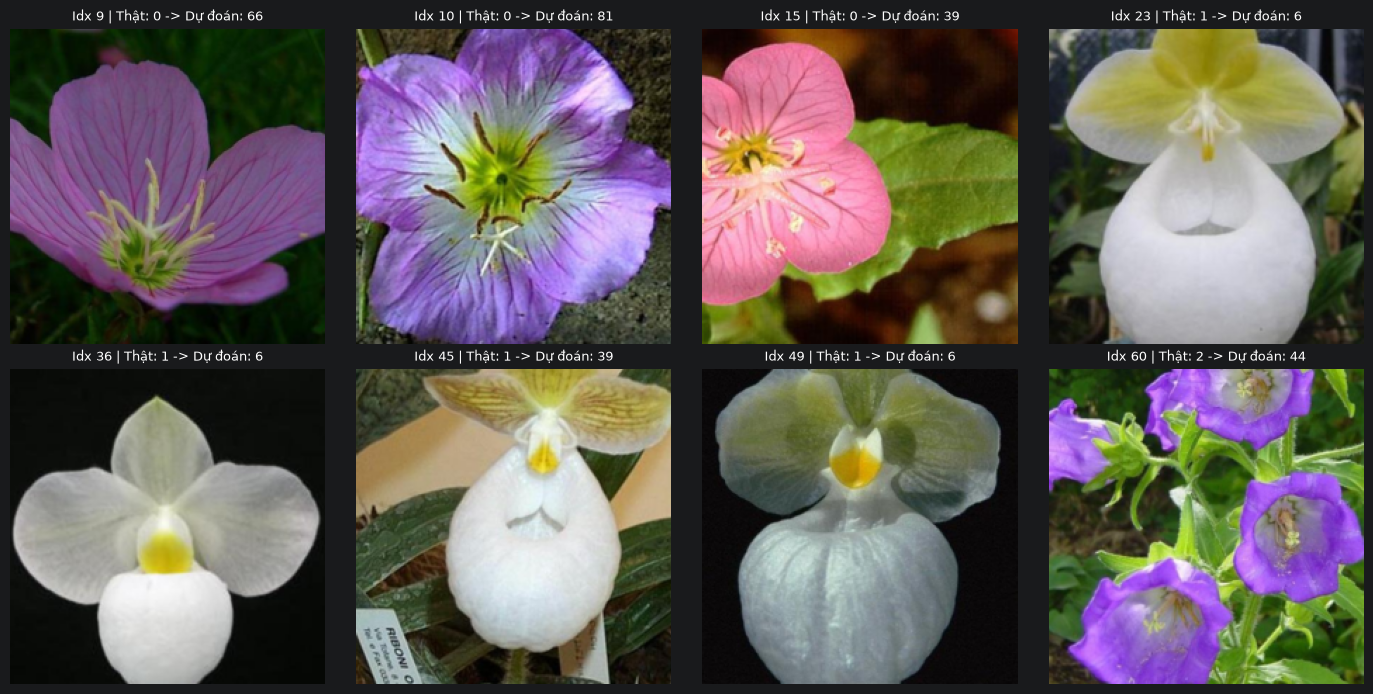

In [10]:
flowers_test = datasets.Flowers102(DATA_DIR, split="test", download=True, transform=eval_transform)
assert len(flowers_test) == 6149
test_loader = make_loader(flowers_test, False)

test_metrics = evaluate(best_model, test_loader)
test_report = pd.DataFrame([{
    "Mô hình": selected_name, "Test loss": test_metrics["loss"], "Test Top-1": test_metrics["top1"],
    "Test Macro-F1": test_metrics["macro_f1"], "Test Top-5": test_metrics["top5"], "N test": len(flowers_test)}])
display(test_report.round(4))
test_report.to_csv(OUTPUT_DIR / "final_test_metrics.csv", index=False)

y_true, y_pred = test_metrics["y_true"], test_metrics["y_pred"]

# Bảng chỉ số theo lớp: 10 lớp F1 thấp nhất
label_names = [f"Flower {i:03d}" for i in range(NUM_CLASSES)]
rep = classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES), target_names=label_names,
                            zero_division=0, output_dict=True)
class_table = pd.DataFrame(rep).T.iloc[:NUM_CLASSES]
print("10 lớp có F1 thấp nhất:")
display(class_table.sort_values("f1-score").head(10).round(3))
class_table.to_csv(OUTPUT_DIR / "test_per_class_metrics.csv")

# Ma trận nhầm lẫn 102x102 (toàn bộ) và ma trận con của 15 lớp nhiều lỗi nhất
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(cm, cmap="Blues")
axes[0].set(title=f"Confusion matrix đầy đủ - {selected_name}", xlabel="Dự đoán", ylabel="Thật")
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.argsort(off.sum(axis=1))[::-1][:15]
sub = cm[np.ix_(top, top)]
axes[1].imshow(sub, cmap="Blues")
axes[1].set_xticks(range(15)); axes[1].set_xticklabels(top, rotation=45)
axes[1].set_yticks(range(15)); axes[1].set_yticklabels(top)
axes[1].set(title="Ma trận con: 15 lớp nhiều lỗi nhất (lỗi sang lớp ngoài 15 lớp này không hiển thị)",
            xlabel="Dự đoán", ylabel="Thật")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150)
plt.show()

# Ảnh dự đoán sai (hiển thị từ ảnh gốc, không cần hoàn tác Normalize)
raw_test = datasets.Flowers102(DATA_DIR, split="test", download=False,
                               transform=transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)]))
wrong = np.where(y_pred != y_true)[0]
print(f"Tổng ảnh dự đoán sai: {len(wrong)} / {len(flowers_test)} ({len(wrong) / len(flowers_test):.2%})")
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.flat, wrong[:8]):
    img, t = raw_test[int(idx)]
    ax.imshow(img)
    ax.set_title(f"Idx {idx} | Thật: {t} -> Dự đoán: {int(y_pred[idx])}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "misclassified_samples.png", dpi=150)
plt.show()

## 10. Lưu/tải checkpoint và suy luận một ảnh
Checkpoint lưu kiến trúc, số lớp, trọng số, chiến lược được chọn, tiền xử lý và `val_loss`; tải lại bằng `weights_only=True` rồi đối chiếu logits.

In [11]:
ckpt_path = OUTPUT_DIR / "flowers102_best_resnet18.pt"
torch.save({
    "architecture": "resnet18", "num_classes": NUM_CLASSES, "selected_strategy": selected_name,
    "state_dict": {k: v.detach().cpu() for k, v in best_model.state_dict().items()},
    "image_size": IMAGE_SIZE, "normalization_mean": MEAN, "normalization_std": STD,
    "val_loss": float(comparison.iloc[0]["Val loss"]),
}, ckpt_path)

payload = torch.load(ckpt_path, map_location="cpu", weights_only=True)
restored = build_resnet18(num_classes=payload["num_classes"], pretrained=False)
restored.load_state_dict(payload["state_dict"])
restored = restored.to(DEVICE).eval()

x, y = flowers_test[0]
with torch.inference_mode():
    before = best_model(x.unsqueeze(0).to(DEVICE)).cpu()
    after = restored(x.unsqueeze(0).to(DEVICE)).cpu()
same = bool(torch.allclose(before, after, atol=1e-5, rtol=1e-5))
assert same
probs = after.softmax(dim=1)[0]
vals, idxs = probs.topk(5)
display(pd.DataFrame({"Lớp dự đoán": idxs.tolist(), "Xác suất": vals.tolist()}))
print("Nhãn thật:", y, "| Reload khớp logits:", same,
      "| Kích thước (MB):", round(ckpt_path.stat().st_size / 1024 ** 2, 1))

,Lớp dự đoán,Xác suất
0,0,0.791562
1,18,0.065022
2,92,0.045098
3,97,0.036811
4,66,0.027643


Nhãn thật: 0 | Reload khớp logits: True | Kích thước (MB): 42.9


## 11. Tóm tắt tự động từ kết quả vừa chạy
Các số liệu dưới đây được in từ biến thực tế, không gõ tay.

In [12]:
best_loss_row = comparison.iloc[0]
best_acc_row = comparison.sort_values("Val Top-1", ascending=False).iloc[0]
scr = comparison[comparison["Chiến lược"] == "Scratch"].iloc[0]
pre = comparison[comparison["Chiến lược"] != "Scratch"]["Val Top-1"]
sel_val = comparison[comparison["Chiến lược"] == selected_name].iloc[0]

print(f"- Val loss thấp nhất: {best_loss_row['Chiến lược']} ({best_loss_row['Val loss']:.4f}).")
print(f"- Val top-1 cao nhất: {best_acc_row['Chiến lược']} ({best_acc_row['Val Top-1']:.2%}).")
if best_loss_row["Chiến lược"] != best_acc_row["Chiến lược"]:
    print("  -> Hai tiêu chí cho thứ hạng khác nhau: loss xét cả độ tự tin, top-1 chỉ xét nhãn đứng đầu.")
print(f"- Scratch: {scr['Val Top-1']:.2%} so với các cấu hình pretrained: {pre.min():.2%} - {pre.max():.2%}.")
print(f"- Mô hình chọn ({selected_name}): val top-1 {sel_val['Val Top-1']:.2%} -> test top-1 {test_metrics['top1']:.2%} "
      f"(chênh {100 * (test_metrics['top1'] - sel_val['Val Top-1']):+.2f} điểm %).")
print(f"- Test loss {test_metrics['loss']:.4f} so với val loss {sel_val['Val loss']:.4f}.")
print(f"- Số ảnh test sai: {len(wrong)}/{len(flowers_test)}; top-5 {test_metrics['top5']:.2%} > top-1 {test_metrics['top1']:.2%}.")

- Val loss thấp nhất: Partial FT (0.6448).
- Val top-1 cao nhất: Full FT (85.29%).
  -> Hai tiêu chí cho thứ hạng khác nhau: loss xét cả độ tự tin, top-1 chỉ xét nhãn đứng đầu.
- Scratch: 20.98% so với các cấu hình pretrained: 83.04% - 85.29%.
- Mô hình chọn (Partial FT): val top-1 83.04% -> test top-1 80.26% (chênh -2.78 điểm %).
- Test loss 0.7247 so với val loss 0.6448.
- Số ảnh test sai: 1214/6149; top-5 94.83% > top-1 80.26%.


## Kết luận (điền sau khi chạy xong, dựa trên bảng ở mục 8 và mục 11)

1. **Scratch vs pretrained:** …
2. **Loss và accuracy cho thứ hạng khác nhau không?** …
3. **Ảnh hưởng của BatchNorm ở eval() và LR theo tầng:** …
4. **Kết quả test của mô hình được chọn và các lớp khó:** …
5. **Giới hạn:** một seed, số epoch không bằng nhau (Probe 25, còn lại 5), chưa tìm kiếm siêu tham số; không suy rộng thành thứ hạng tuyệt đối.